# Assignment Problems: Day 7
The following problems require access to the file named ‘Dataset_Day7.csv’, provided with this assignment. (Use Random State = 203)

The datasets include data from 768 women with several medical predictor variables and one target variable(‘Outcome’). The classification goal is to predict whether or not the patients in the dataset have diabetes or not.

For columns: Glucose, BloodPressure, BMI, DiabetesPedigreeFunction

If the column value is 0, then they should be considered as missing data.

In [1]:
import numpy as np
import pandas as pd
from math import log
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, log_loss, precision_recall_curve, accuracy_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

* Firstly, replace all Missing values with relevant figures.
* Then remove all existing outliers and get the final data for classification.

In [2]:
data = pd.read_csv("Dataset_Day7.csv")

# Missing data treatment
print('Before Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    data[col][data[col]==0] = data[col].median()
print('\nAfter Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))

outlier = pd.DataFrame([])
#Standard scaling of the continuous columns only
for i in ['BMI', 'DiabetesPedigreeFunction', 'Glucose', 'Pregnancies', 'BloodPressure', 'Age'] :
    data[i] = (data[i] - data[i].mean())/data[i].std()
outlier = data[(data["BMI"]>3)|(data["BMI"]<-3)|
               (data["DiabetesPedigreeFunction"]>3)|(data["DiabetesPedigreeFunction"]<-3)|
               (data["Pregnancies"]>3)|(data["Pregnancies"]<-3)|(data["Age"]>3)|(data["Age"]<-3)|
               (data["Glucose"]>3)|(data["Glucose"]<-3)|(data["BloodPressure"]>3)|(data["BloodPressure"]<-3)]
OutlierFreeData = data.drop(outlier.index,axis=0)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(data)*100))


# for i in ['BMI', 'DiabetesPedigreeFunction'] :#'Glucose', 'Pregnancies', 'BloodPressure', 'Age'] :
#     data[i] = (data[i] - data[i].mean())/data[i].std()
# for i in ['Glucose', 'Pregnancies', 'BloodPressure', 'Age'] :
#     data[i] = data[i] /10
# # Outlier Detection using z-score
# outlier1 = data[(data["BMI"]>3)|(data["BMI"]<-3)|
#                (data["DiabetesPedigreeFunction"]>3)|(data["DiabetesPedigreeFunction"]<-3)]#|
# #               (data["Pregnancies"]>3)|(data["Pregnancies"]<-3)||(data["Age"]>3)|(data["Age"]<-3)
# #               (data["Glucose"]>3)|(data["Glucose"]<-3)|(data["BloodPressure"]>3)|(data["BloodPressure"]<-3)]
# OutlierFreeData = data.drop(outlier1.index,axis=0)
# for i in ['Glucose', 'Pregnancies', 'BloodPressure', 'Age']:
#     z_score = (OutlierFreeData[i] - OutlierFreeData[i].mean())/OutlierFreeData[i].std()
#     outlier2 = OutlierFreeData[(z_score>3)|(z_score<-3)]
# OutlierFreeData.drop(outlier2.index,axis=0,inplace = True)
# print("\nno. of Outlier",(len(outlier1)+len(outlier2)), "\n% of Outlier = ", str((len(outlier1)+len(outlier2))/len(data)*100))


Before Missing Data Treatment
Glucose  =  5
BloodPressure  =  35
BMI  =  11
DiabetesPedigreeFunction  =  0

After Missing Data Treatment
Glucose  =  0
BloodPressure  =  0
BMI  =  0
DiabetesPedigreeFunction  =  0

no. of Outlier 30 
% of Outlier =  3.90625


C:\Users\nikhi\AppData\Local\Temp\ipykernel_11616\1612197773.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col][data[col]==0] = data[col].median()


* Split the data into 70% training and 30% testing data. Then, create a logistic regression model with target variable as ‘Outcome’.
* Print the default model performance metrics: Accuracy, Precision, Recall, F1Score & AIC

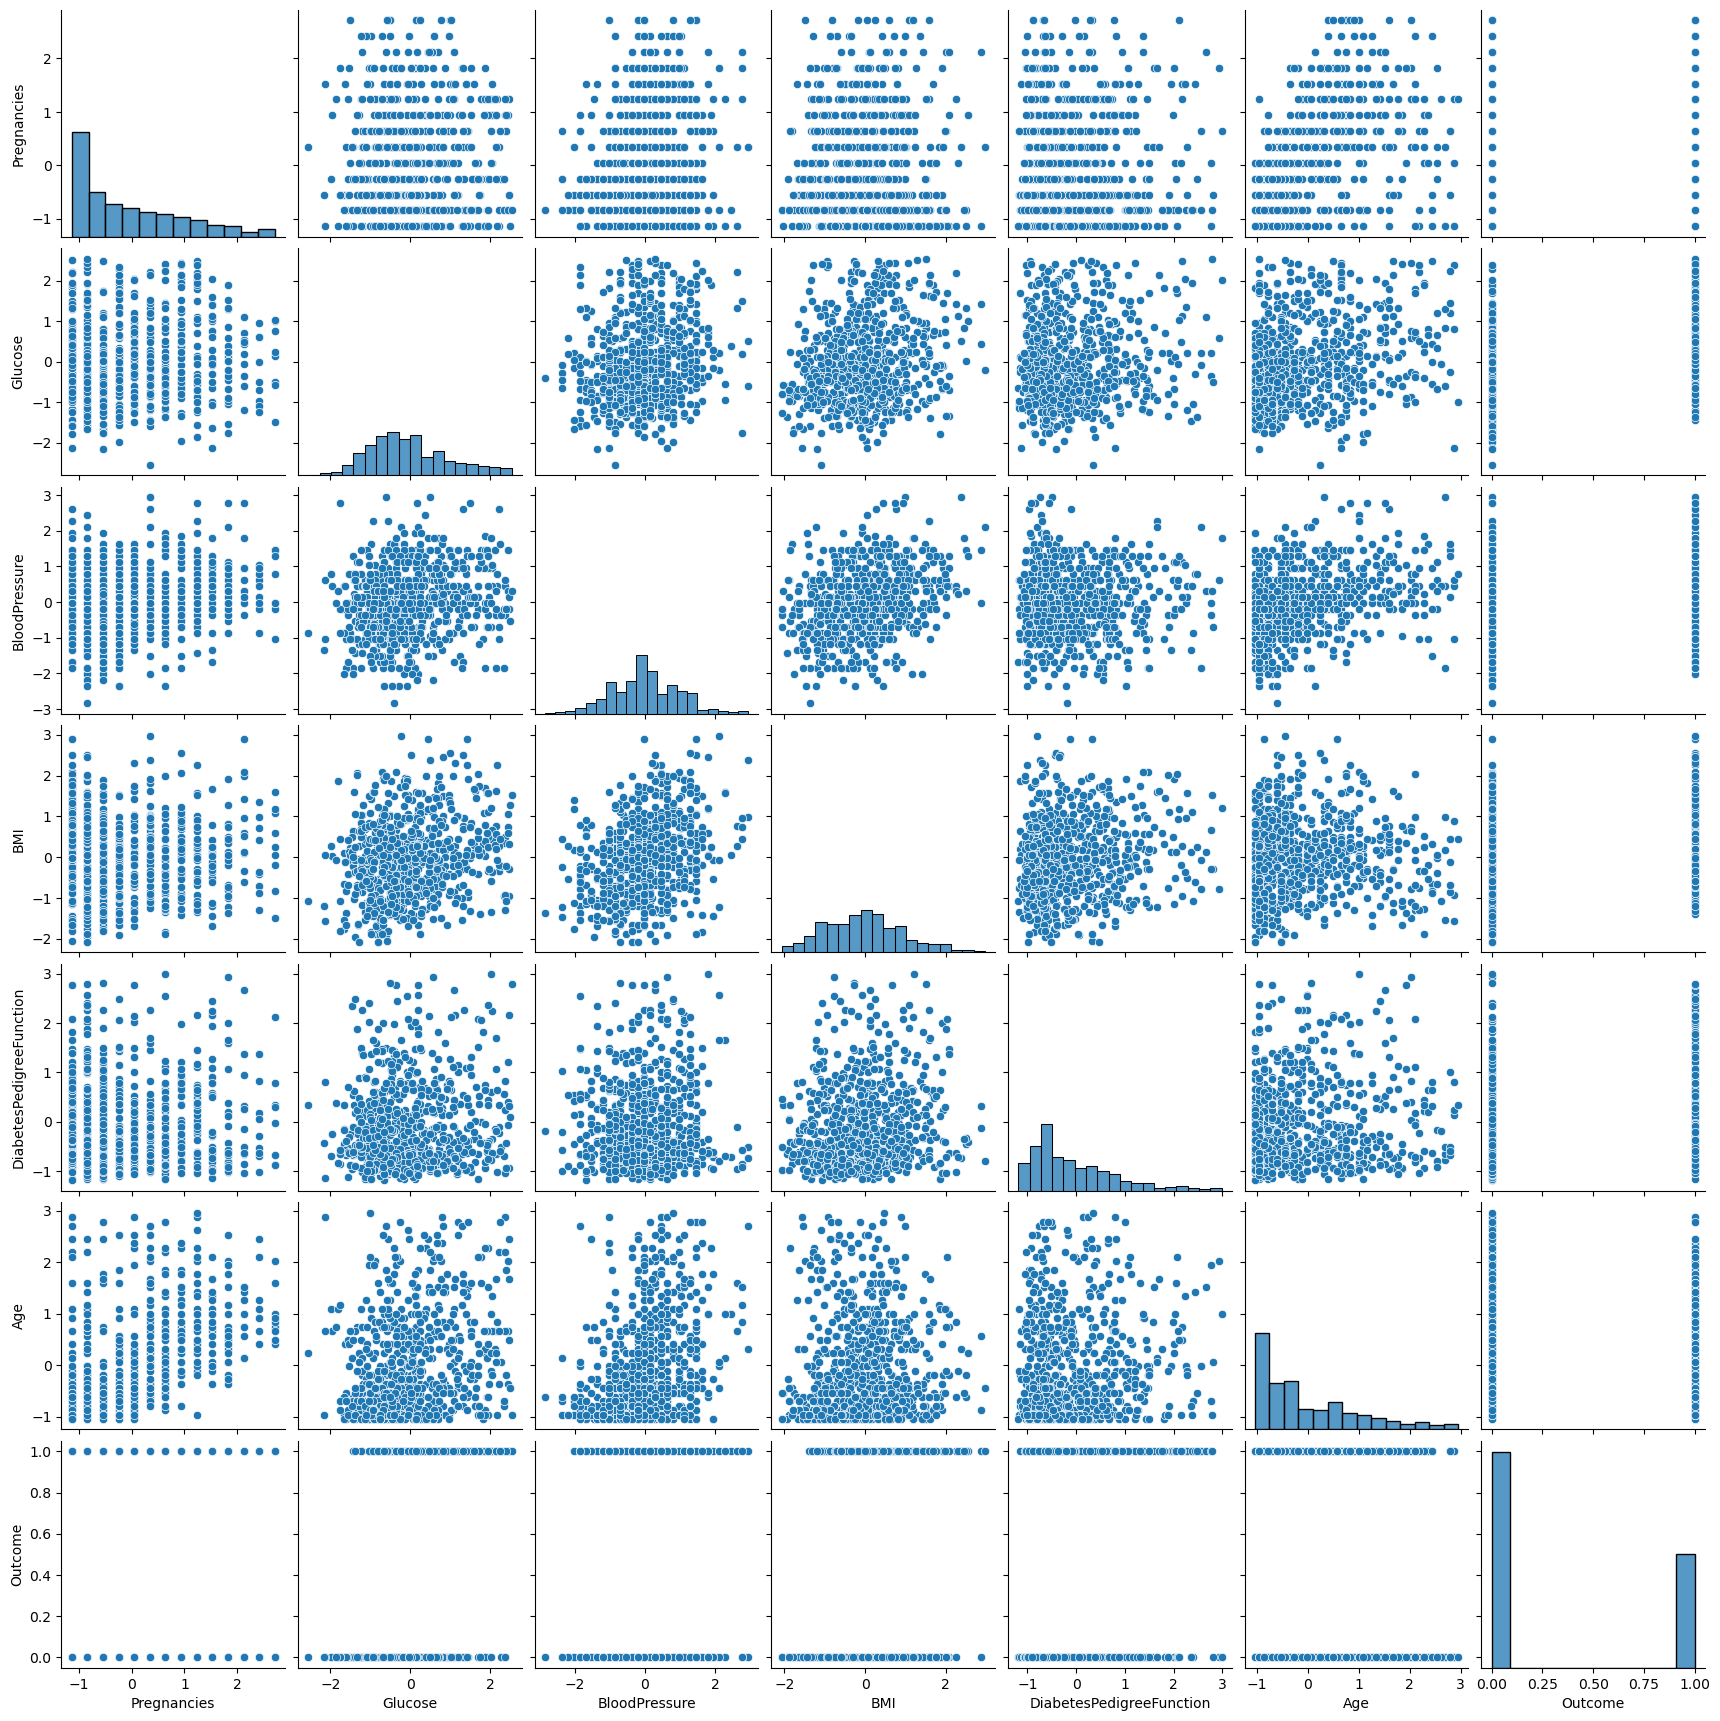

In [3]:
sns.pairplot(OutlierFreeData)

In [4]:
OutlierFreeData.corr()

,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.119855,0.210778,0.033791,0.011111,0.555258,0.214054
Glucose,0.119855,1.000000,0.208097,0.219998,0.100247,0.271698,0.495811
BloodPressure,0.210778,0.208097,1.000000,0.309381,0.026774,0.342387,0.176175
BMI,0.033791,0.219998,0.309381,1.000000,0.127388,0.055202,0.290752
DiabetesPedigreeFunction,0.011111,0.100247,0.026774,0.127388,1.000000,0.066710,0.202476
Age,0.555258,0.271698,0.342387,0.055202,0.066710,1.000000,0.256544
Outcome,0.214054,0.495811,0.176175,0.290752,0.202476,0.256544,1.000000


Accuracy =  77.92792792792793
Precision =  68.85245901639344
Recall =  58.333333333333336
F1-Score =  63.1578947368421
AIC =  5.437690046073589


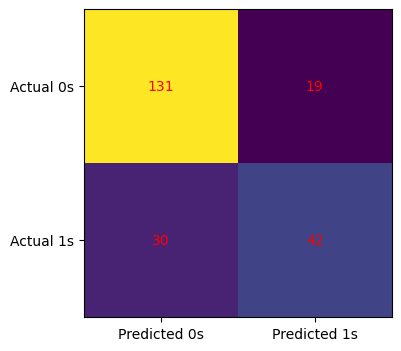

In [5]:
# Spliting of data 7:3
X = OutlierFreeData.drop("Outcome",axis=1)
y = OutlierFreeData["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30, random_state=42)

# Logistic Regression model
model = LogisticRegression(random_state=45) 
model.fit(X_train, y_train)
y_pred = model.predict(X_test) #default threshold value is 0.5
f1_score = 2*precision_score(y_test,y_pred)*recall_score(y_test,y_pred)/(precision_score(y_test,y_pred)+recall_score(y_test,y_pred))
print("Accuracy = ", accuracy_score(y_test,y_pred)*100)
print("Precision = ", precision_score(y_test,y_pred)*100)
print("Recall = ", recall_score(y_test,y_pred)*100)
print("F1-Score = ", f1_score*100)
print("AIC = ", (2/len(y_pred)*log_loss(y_test,y_pred)/len(y_pred) + 2*len(X_train.columns)/len(y_pred))*100)

# confusion matrix plotting
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm)
#ax.grid(False)
ax.xaxis.set(ticks=(0, 1), ticklabels=('Predicted 0s', 'Predicted 1s'))
ax.yaxis.set(ticks=(0, 1), ticklabels=('Actual 0s', 'Actual 1s'))
ax.set_ylim(1.5, -0.5)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='red')
plt.show()

* Plot a F1_score vs threshold curve. Find the threshold for which f1-score is the highest.

For Optimum Threshold =  0.21822543346199966
Accuracy =  72.52252252252252
Precision =  54.400000000000006
Recall =  94.44444444444444
F1-Score =  69.03553299492386
AIC =  5.445596488686206


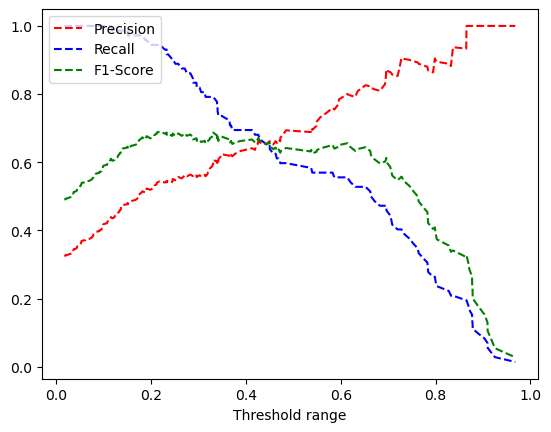

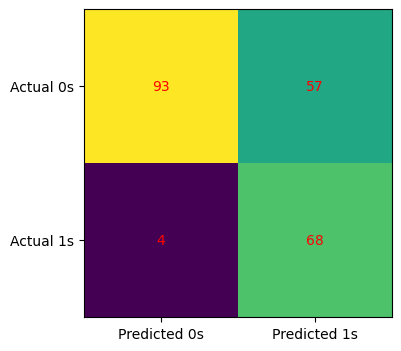

In [6]:
y_scores = model.predict_proba(X_test)[:,1]
prec, rec, tre = precision_recall_curve(y_test,y_scores)
f_score = (2*prec*rec)/(prec+rec)
index = np.where(f_score==max(f_score))
y_pred = (y_scores >= tre[index]).astype(int)

# Plotting graph
plt.plot(tre,prec[:-1],'r--',label='Precision')
plt.plot(tre,rec[:-1],'b--',label='Recall')
plt.plot(tre,f_score[:-1],'g--',label='F1-Score')
plt.xlabel('Threshold range')
plt.legend(loc='upper left')


print("For Optimum Threshold = ", tre[index][0])
print("Accuracy = ", accuracy_score(y_test,y_pred)*100)
print("Precision = ", prec[index][0]*100)
print("Recall = ", rec[index][0]*100)
print("F1-Score = ", max(f_score)*100)
print("AIC = ", (2/len(y_pred)*log_loss(y_test,y_pred)/len(y_pred) + 2*len(X_train.columns)/len(y_pred))*100)

# confusion matrix plotting
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm)
#ax.grid(False)
ax.xaxis.set(ticks=(0, 1), ticklabels=('Predicted 0s', 'Predicted 1s'))
ax.yaxis.set(ticks=(0, 1), ticklabels=('Actual 0s', 'Actual 1s'))
ax.set_ylim(1.5, -0.5)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='red')
plt.show()

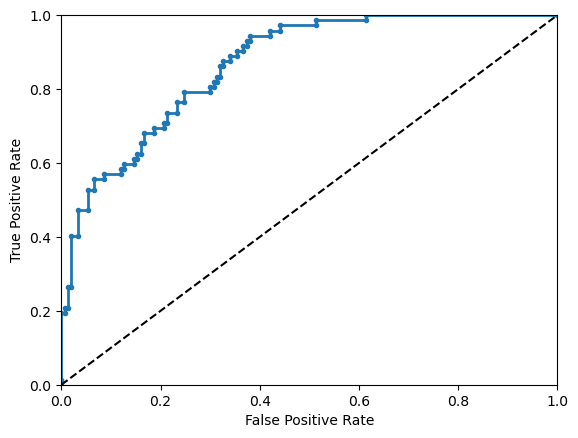

In [7]:
y_scores = model.predict_proba(X_test)
fpr, tpr, threshold= roc_curve(y_test, y_scores[:,1])
def plot_roc_curve(fpr, tpr):
    plt.clf()
    plt.plot(fpr, tpr, linewidth=2, marker='.', label='Logistic')
    plt.plot([0,1], [0,1], 'k--')
    plt.axis([0,1,0,1])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
plot_roc_curve(fpr, tpr)
plt.show()

Name - Nikhil Khatri

SIC  - 21BCSA92